Saving archive (5).zip to archive (5) (3).zip
Stock: Apple (AAPL)
Records: 2000
Date range: 2016-07-11 to 2024-06-20
Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0033 - val_loss: 0.0079
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0135 - val_loss: 0.0021
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0023 - val_loss: 0.0054
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0018 - val_loss: 0.0029
Epoch 5/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 6.1364e-04 - val_loss: 0.0026
Epoch 6/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 7.5711e-04 - val_loss: 0.0033
Epoch 7/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0012 - val_loss: 0.0035
Epoch 8/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0013 - val_loss: 0.0031
Epoch 9/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0012 - val_loss: 0.0029
Epoch 10/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0011 - val_loss: 0.0027
Epoch 11/15
44/44 ━━━━━━

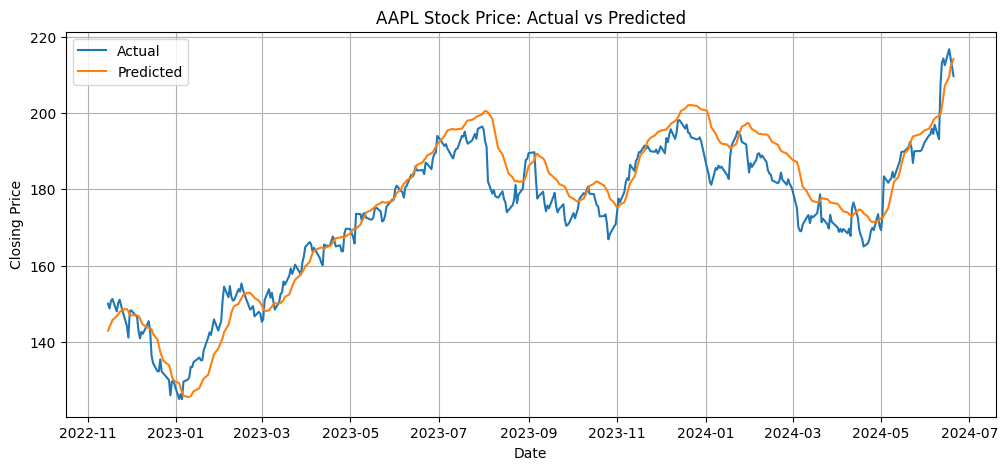

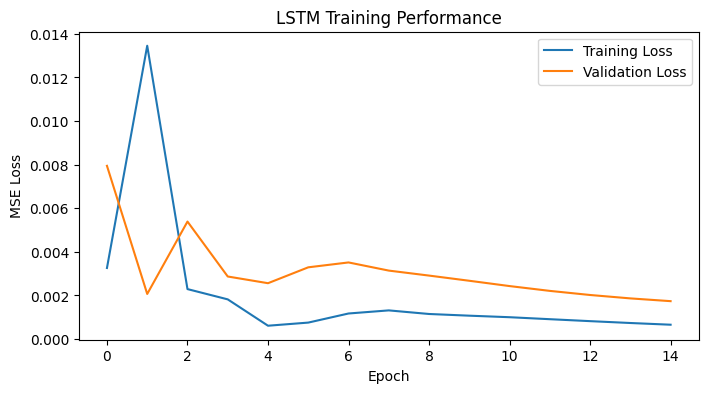


Last historical date: 2024-06-20
Predicted next closing price: 209.4714


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

!pip -q install tensorflow scikit-learn

import os, zipfile, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

uploaded = files.upload()
filename = next(iter(uploaded))
folder = "/content/stock_data"
os.makedirs(folder, exist_ok=True)

if zipfile.is_zipfile(filename):
    with zipfile.ZipFile(filename) as z:
        z.extractall(folder)
    csv_files = glob.glob(folder + "/**/*.csv", recursive=True)
else:
    csv_files = [filename]

if not csv_files:
    raise ValueError("No CSV file found.")

df = pd.read_csv(csv_files[0])
df.columns = [str(c).strip().lower() for c in df.columns]

date_col = next((c for c in df.columns if c in ["date", "datetime", "timestamp"]), None)
if date_col is None and "unnamed: 0" in df.columns:
    date_col = "unnamed: 0"
if date_col is None:
    date_col = df.columns[0]

close_col = next((c for c in df.columns if c in ["close", "adjclose", "adj close", "closingprice"]), None)

if close_col is None:
    raise ValueError("Closing price column not found: " + str(df.columns.tolist()))

df = df[[date_col, close_col]].copy()
df.columns = ["Date", "Close"]
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna().query("Close > 0")
df = df.drop_duplicates("Date").sort_values("Date").tail(2000).reset_index(drop=True)

if len(df) < 2000:
    raise ValueError(f"Only {len(df)} valid records found.")

print("Stock: Apple (AAPL)")
print("Records:", len(df))
print("Date range:", df.Date.min().date(), "to", df.Date.max().date())

prices = df[["Close"]].values
split, window = 1600, 60
scaler = MinMaxScaler().fit(prices[:split])
data = scaler.transform(prices)

X = np.array([data[i-window:i] for i in range(window, len(data))])
y = data[window:, 0]
X_train, y_train = X[:split-window], y[:split-window]
X_test, y_test = X[split-window:], y[split-window:]

tf.random.set_seed(42)
model = Sequential([Input(shape=(window, 1)), LSTM(32), Dense(1)])
model.compile(optimizer="adam", loss="mse")
history = model.fit(X_train, y_train, epochs=15, batch_size=32,
                    shuffle=False, validation_split=0.1, verbose=1)

pred = scaler.inverse_transform(model.predict(X_test, verbose=0))
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

print("\nMAE:", round(mean_absolute_error(actual, pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, pred)), 4))

plt.figure(figsize=(12, 5))
plt.plot(df["Date"].iloc[split:], actual, label="Actual")
plt.plot(df["Date"].iloc[split:], pred, label="Predicted")
plt.title("AAPL Stock Price: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training Performance")
plt.legend()
plt.show()

future_scaler = MinMaxScaler().fit(prices)
future_data = future_scaler.transform(prices)
X_all = np.array([future_data[i-window:i] for i in range(window, len(future_data))])
y_all = future_data[window:, 0]

model.fit(X_all, y_all, epochs=5, batch_size=32, shuffle=False, verbose=0)
next_scaled = model.predict(future_data[-window:].reshape(1, window, 1), verbose=0)
next_price = future_scaler.inverse_transform(next_scaled)[0, 0]

print("\nLast historical date:", df["Date"].iloc[-1].date())
print("Predicted next closing price:", round(float(next_price), 4))

result = pd.DataFrame({
    "Date": df["Date"].iloc[split:].values,
    "Actual": actual.ravel(),
    "Predicted": pred.ravel()
})
result.to_csv("AAPL_predictions.csv", index=False)
files.download("AAPL_predictions.csv")
